# Qwen2.5-0.5B-Instruct 的 SFT 与 LoRA：从数据到独立推理

## 实验总览

本实验在已有指令模型 **Qwen2.5-0.5B-Instruct** 上开展监督微调（Supervised Fine-Tuning，SFT），用两条问答样本学习数据格式、Loss、梯度更新与推理流程。SFT 定义“根据什么监督信号学习”，LoRA 定义“用哪些参数适配模型”：二者是训练目标与参数更新方式的配合，并不是两种互斥的训练任务。

本实验保留基础模型权重，向选定线性层接入低秩增量，只优化少量 Adapter 参数。学习重点是把下列流程串成闭环，而不是用极小数据集证明模型能力提升：

> 聊天模板 → 完整对话与 Prompt 编码 → 标签屏蔽 → 动态 Padding 与 Batch → 基础模型 Loss → 接入 LoRA → 单步更新演示 → 重置模型 → 10 个 Epoch 训练与验证 → Loss 曲线与生成对比 → 保存、重载 Adapter → 独立脚本推理。

### 阅读目录

1. Tokenizer 与 Chat Template
2. 训练样本、标签与 Padding
3. Dataset、DataLoader 与张量
4. 模型前向传播与 Causal LM Loss
5. LoRA 原理与配置
6. 单步训练与实验重置
7. 验证函数与多 Epoch 训练
8. Loss 曲线与结果解读
9. 文本生成与推理
10. 基础模型与 LoRA 的比较
11. 保存与重新加载 Adapter
12. 独立推理脚本与 Python 环境
13. 总结与下一阶段

### 文件之间的关系

以下是当前模块中与本实验直接相关的文件；Adapter 目录还包含其他分词器配套文件：

```text
llm-finetuning/
├── qwen_sft_lora.ipynb                  # 数据、手写训练、评估与保存重载
├── inference_lora.py                   # 加载已有 Adapter 的交互推理脚本
└── qwen2_5_0_5b_lora_adapter/
    ├── adapter_config.json             # Adapter 结构与基础模型标识
    ├── adapter_model.safetensors       # Adapter 参数
    ├── tokenizer.json                 # Tokenizer 资源之一
    └── chat_template.jinja             # 保存的聊天模板
```

**证据范围**：下文数值和回答均引用现有保存输出。本次只补充 Markdown，不执行训练、安装依赖或重新下载模型。训练集与验证集各只有两条样本，没有独立的大规模测试集；当前是普通 LoRA，没有量化加载，也没有实现 QLoRA、Trainer 或 SFTTrainer。

## 1. Tokenizer 与 Chat Template

### 从文本到模型可计算的输入

文本是字符串；Token 是 Tokenizer 划分出的片段，可能是子词、标点、空格或特殊标记；Token ID 是该片段在词表中的整数编号。Token 数不等于汉字数或英文单词数，整数 ID 本身也不是语义向量：模型随后通过 Embedding 查表得到浮点表示。

下面的 `messages` 是按顺序排列的消息列表，每项用 `role` 表示发言角色，用 `content` 保存文本。本例显式提供了 user 问题与 assistant 标准答案，作为一条完整训练对话。

`apply_chat_template()` 根据模型配套模板把角色和内容组织为模型熟悉的对话格式。本 Cell 使用 `tokenize=False`，只展示格式化字符串，不返回 Token ID。保存输出还出现了默认 system 消息，这来自当前 Tokenizer 的模板；并不是代码显式增加了一条 system 数据，也不能假设所有模型模板都会这样处理。

| 参数 / 标记 | 本例含义 |
|---|---|
| `add_generation_prompt=False` | 已经有 assistant 答案，不再追加一个等待续写的 assistant 开头 |
| `<|im_start|>`、`<|im_end|>` | 模板中的消息边界标记，不能当作普通自然语言内容忽略 |
| `MODEL_NAME` | 同时决定模型和配套 Tokenizer 的加载标识 |

后续推理只给 user 问题，因此会使用 `add_generation_prompt=True`：添加等待模型填写答案的 assistant 前缀。它添加的是角色起始提示，并不会自动生成答案。

In [40]:
from transformers import AutoTokenizer
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

messages = [{"role": "user", "content": "2 + 3 等于多少？"},
            {"role": "assistant", "content": "5"}]
formatted_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=False
)

print(formatted_text)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
2 + 3 等于多少？<|im_end|>
<|im_start|>assistant
5<|im_end|>



## 2. 训练样本、标签与 Padding

### 2.1 先确定“看见什么”，再确定“学习预测什么”

本 Cell 将同一对话编码两次：完整对话含标准答案；`messages[:-1]` 只保留 Prompt，并加上等待作答的 assistant 前缀。`assert torch.equal(...)` 检查 Prompt 编码确实是完整序列的前缀，使“按前缀长度屏蔽标签”的边界有依据，而不是凭字符串长度猜测。

| 字段 | 本例 shape | 作用 |
|---|---|---|
| `input_ids` | `(1, 42)` | 完整对话的整数 Token ID，包含问题、答案和模板标记 |
| `attention_mask` | `(1, 42)` | 标记有效输入位置；本例无 Padding，因此全为 1 |
| `labels` | `(1, 42)` | 目标 Token ID；不参与 Loss 的位置改为 -100 |

`labels = input_ids.clone()` 复制目标，随后把 Prompt 对应位置设为 **-100**。-100 是交叉熵使用的忽略标签，不是合法词表 ID，不会送入 Embedding。它让训练集中在 assistant 回答区域，而不是要求模型连用户问题和系统提示一起背下来。

这里要区分两种屏蔽：

- `labels=-100`：该目标位置不贡献监督 Loss，但对应 Prompt 仍保留在输入中，为回答提供上下文。
- `attention_mask=0`：输入中的填充位置不应作为有效上下文被关注。它与模型内部的因果遮罩也不是同一个概念。

保存输出显示受监督文本是 `5<|im_end|>` 后接换行。因此本实验不仅监督答案字符，也监督答案后的消息结束与换行 Token；不能把这里的 Loss 理解为只对数字“5”评分。标签暂时保持与原序列对齐，预测下一 Token 所需的移位由后面的 Causal LM 模型内部完成。

In [41]:
import torch

encoded = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=False,
    return_dict=True,
    return_tensors="pt"
)

input_ids = encoded["input_ids"]
attention_mask = encoded["attention_mask"]
prompt_encoded = tokenizer.apply_chat_template(
    messages[:-1],
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)

prompt_ids = prompt_encoded["input_ids"]
assert torch.equal(
    input_ids[:, :prompt_ids.shape[1]],
    prompt_ids
), "提示部分与完整序列的 Token 不一致，请检查聊天模板。"

labels = input_ids.clone()
labels[:, :prompt_ids.shape[1]] = -100

print("input_ids shape:", input_ids.shape)
print("attention_mask shape:", attention_mask.shape)
print("labels shape:", labels.shape)

print("input_ids:", input_ids.tolist())
print("attention_mask:", attention_mask.tolist())
print("labels:", labels.tolist())

print("参与 Loss 的文本:", tokenizer.decode(labels[0][labels[0] != -100],
        skip_special_tokens=False))

input_ids shape: torch.Size([1, 42])
attention_mask shape: torch.Size([1, 42])
labels shape: torch.Size([1, 42])
input_ids: [[151644, 8948, 198, 2610, 525, 1207, 16948, 11, 3465, 553, 54364, 14817, 13, 1446, 525, 264, 10950, 17847, 13, 151645, 198, 151644, 872, 198, 17, 488, 220, 18, 10236, 255, 231, 34204, 100430, 11319, 151645, 198, 151644, 77091, 198, 20, 151645, 198]]
attention_mask: [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]
labels: [[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 20, 151645, 198]]
参与 Loss 的文本: 5<|im_end|>



### 2.2 用整数玩具示例理解 Padding

下面暂时用两条长度分别为 5、7 的整数序列演示批处理，并不表示这些整数对应真实 Qwen 对话。为了组成规则的二维张量，较短序列在右侧补齐到当前最长长度，得到 `(B, T)=(2, 7)`。

三个字段必须同步处理：输入补 pad ID，输入 mask 补 0，标签补 -100。这样占位元素既不会被当作有效历史，也不会成为预测目标。示例里的填充值 0 仅用于演示；下一段实际数据预处理会使用 Tokenizer 的 `pad_token_id`，不能把 0 当成 Qwen 的通用 Padding ID。

Padding 解决的是 Batch 内长度不一致的问题，不等于截断。当前代码没有设置训练序列长度上限或实现截断策略；扩展长文本数据时需要另行设计，而不是认为这里已经处理了任意长度输入。

In [42]:
import torch

sample_a = [11, 22, 33, 44, 55]
sample_b = [11, 22, 33, 44, 55, 66, 77]

max_length = max(len(sample_a), len(sample_b))
pad_a = max_length - len(sample_a)
pad_b = max_length - len(sample_b)
input_a = sample_a + [0] * pad_a
input_b = sample_b + [0] * pad_b

mask_a = [1] * len(sample_a) + [0] * pad_a
mask_b = [1] * len(sample_b) + [0] * pad_b
labels_a = [-100, -100, -100, 44, 55] + [-100] * pad_a
labels_b = [-100, -100, -100, 44, 55, 66, 77]

input_ids = torch.tensor([input_a, input_b])
attention_mask = torch.tensor([mask_a, mask_b])
labels = torch.tensor([labels_a, labels_b])

print("input_ids:")
print(input_ids)

print("attention_mask:")
print(attention_mask)

print("labels:")
print(labels)

print("input_ids shape:", input_ids.shape)

input_ids:
tensor([[11, 22, 33, 44, 55,  0,  0],
        [11, 22, 33, 44, 55, 66, 77]])
attention_mask:
tensor([[1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1]])
labels:
tensor([[-100, -100, -100,   44,   55, -100, -100],
        [-100, -100, -100,   44,   55,   66,   77]])
input_ids shape: torch.Size([2, 7])


### 2.3 将两条真实问答整理为 SFT 样本

训练数据是“2 + 3 → 5”与“法国首都 → 巴黎。”两条单轮对话。处理顺序与前面的单样本演示一致：

1. 用完整对话得到 `full_ids`，用去掉答案的对话得到 `prompt_ids`。
2. 检查前缀一致，复制标签并屏蔽 Prompt，存入 `encoded_examples`。
3. 取本批最长长度，使用真实 pad ID 右侧补齐，并生成 mask 与标签。
4. 用 `torch.long` 将三个列表转为整数张量；Token 索引与交叉熵目标需要整数类型。

如果 Tokenizer 没有 pad Token，代码将其设为 eos Token。**ID 相同不代表职责相同**：本代码按实际长度构造 mask，填充位置为 0；真实文本末尾标记仍是有效输入，其标签也可能参与监督。

保存的 Batch shape 都是 `(2, 42)`。这只是当前两条文本编码后的长度，换数据时会改变。此处显式构造的 `batch_input_ids` 等变量将用于首次基础模型前向和单步训练演示；后续正式循环改为从 DataLoader 取 Batch。

In [43]:

import torch
training_messages = [
    [{"role": "user", "content": "2 + 3 等于多少？"},
        {"role": "assistant", "content": "5"}],
    [{"role": "user", "content": "法国的首都是哪里？"},
        {"role": "assistant", "content": "巴黎。"}]
]
encoded_examples = []

for sample_messages in training_messages:
    full_ids = tokenizer.apply_chat_template(
        sample_messages,
        tokenize=True,
        add_generation_prompt=False
    )

    prompt_ids = tokenizer.apply_chat_template(
        sample_messages[:-1],
        tokenize=True,
        add_generation_prompt=True
    )

    assert full_ids[:len(prompt_ids)] == prompt_ids

    sample_labels = full_ids.copy()
    sample_labels[:len(prompt_ids)] = [-100] * len(prompt_ids)

    encoded_examples.append({
        "input_ids": full_ids,
        "labels": sample_labels
    })

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
pad_token_id = tokenizer.pad_token_id

max_length = max(
    len(example["input_ids"])
    for example in encoded_examples
)

batch_input_ids = []
batch_attention_mask = []
batch_labels = []

for example in encoded_examples:
    ids = example["input_ids"]
    target_labels = example["labels"]
    padding_length = max_length - len(ids)

    batch_input_ids.append(
        ids + [pad_token_id] * padding_length
    )
    batch_attention_mask.append(
        [1] * len(ids) + [0] * padding_length
    )
    batch_labels.append(
        target_labels + [-100] * padding_length
    )

batch_input_ids = torch.tensor(batch_input_ids, dtype=torch.long)
batch_attention_mask = torch.tensor(batch_attention_mask, dtype=torch.long)
batch_labels = torch.tensor(batch_labels, dtype=torch.long)

print("input_ids shape:", batch_input_ids.shape)
print("attention_mask shape:", batch_attention_mask.shape)
print("labels shape:", batch_labels.shape)

for i, example in enumerate(encoded_examples):
    target_ids = [
        token_id
        for token_id in example["labels"]
        if token_id != -100
    ]

    print(f"\n样本 {i + 1}")
    print("完整对话：")
    print(tokenizer.decode(
        example["input_ids"],
        skip_special_tokens=False
    ))

    print("参与 Loss 的文本：")
    print(tokenizer.decode(
        target_ids,
        skip_special_tokens=False
    ))

input_ids shape: torch.Size([2, 42])
attention_mask shape: torch.Size([2, 42])
labels shape: torch.Size([2, 42])

样本 1
完整对话：
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
2 + 3 等于多少？<|im_end|>
<|im_start|>assistant
5<|im_end|>

参与 Loss 的文本：
5<|im_end|>


样本 2
完整对话：
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
法国的首都是哪里？<|im_end|>
<|im_start|>assistant
巴黎。<|im_end|>

参与 Loss 的文本：
巴黎。<|im_end|>



## 3. Dataset、DataLoader 与张量

`SFTDataset` 管理“有哪些样本”：`__len__` 返回数量，`__getitem__` 按索引返回一个含输入 ID 与标签的字典。它没有新增下载、分词或训练逻辑，因为样本已提前编码。

`DataLoader` 管理“如何按批取样”：本例 `batch_size=2`、`shuffle=True`，每个 Epoch 遍历两条训练样本。`collate_fn` 接收本批样本列表，在本批最长序列上做**动态 Padding**，补出 mask，并把变长 Python 列表堆成同形状张量。

| 层次 | 当前表示 | 职责 |
|---|---|---|
| 一条样本 | 字典中的变长 ID 列表与标签列表 | 保留一条对话的边界和监督区域 |
| 一个 Batch | 三个 `(B, T)` 张量 | 同时处理多条样本 |
| 模型输入 | 设备一致的整数张量 | Embedding 索引、并行计算与自动求导流程 |

保存输出确认训练样本数为 **2**、每个 Epoch 为 **1 个 Batch**，三个字段均是 `torch.int64`。shuffle 改变取样顺序，并不增加数据量；本例两条样本每轮仍放在同一个 Batch。

张量提供统一的 shape、dtype、设备与底层运算接口，才能进入 PyTorch 模型。此处 collate 返回 CPU 张量，训练时还要通过 `.to(device)` 移到模型所在设备；它不会自动移动模型，也不会改变 Token 的语义。

In [44]:
from torch.utils.data import Dataset, DataLoader

class SFTDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]

def collate_fn(examples):
    max_length = max(
        len(example["input_ids"])
        for example in examples
    )

    batch_input_ids = []
    batch_attention_mask = []
    batch_labels = []

    for example in examples:
        ids = example["input_ids"]
        labels = example["labels"]
        padding_length = max_length - len(ids)
        batch_input_ids.append(
            ids + [pad_token_id] * padding_length
        )
        batch_attention_mask.append(
            [1] * len(ids) + [0] * padding_length
        )
        batch_labels.append(
            labels + [-100] * padding_length
        )

    return {
        "input_ids": torch.tensor(
            batch_input_ids, dtype=torch.long
        ),
        "attention_mask": torch.tensor(
            batch_attention_mask, dtype=torch.long
        ),
        "labels": torch.tensor(
            batch_labels, dtype=torch.long
        )
    }

train_dataset = SFTDataset(encoded_examples)
train_dataloader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

print("训练样本数量:", len(train_dataset))
print("每个 Epoch 的 Batch 数量:", len(train_dataloader))

batch = next(iter(train_dataloader))
for name, tensor in batch.items():
    print(
        f"{name}: shape={tuple(tensor.shape)}, "
        f"dtype={tensor.dtype}"
    )

训练样本数量: 2
每个 Epoch 的 Batch 数量: 1
input_ids: shape=(2, 42), dtype=torch.int64
attention_mask: shape=(2, 42), dtype=torch.int64
labels: shape=(2, 42), dtype=torch.int64


## 4. 模型前向传播与 Causal LM Loss

`AutoModelForCausalLM.from_pretrained(MODEL_NAME)` 根据配置创建带语言模型预测头的模型，并加载已有权重；不是在这里从随机参数训练 Qwen。代码将模型与输入移到同一设备，保存输出记录的设备为 **cuda**。

### 4.1 Logits 与目标之间的关系

输入 `(B,T)` 经 Embedding 和 Decoder 后得到隐藏状态，再由语言模型头输出 `(B,T,V)` 的 Logits。本例为 **(2, 42, 151936)**：每个输入位置都给出词表上的未归一化分数，不是已经归一化的概率或答案正确率。

传入 `labels` 后，模型还返回 `outputs.loss`。对标准因果语言建模，位置 $t$ 的输出预测位置 $t+1$ 的 Token，可写为：

$$
\mathcal{S}=\{(b,t)\mid 0\le t<T-1,\; y_{b,t+1}\ne -100\},
$$

$$
\mathcal{L}=-\frac{1}{|\mathcal{S}|}
\sum_{(b,t)\in\mathcal{S}}
\log\operatorname{softmax}(z_{b,t,:})_{y_{b,t+1}}.
$$

其中 $z$ 是 Logits，$y$ 是 labels，$\mathcal{S}$ 只包含有效监督目标。当前调用未额外指定 Loss 归一化参数，可按有效目标 Token 的平均交叉熵理解。Transformers 内部完成预测与标签的移位；这里不应再手动把 labels 移位一次。最后一个 Prompt 位置的输出可以用于预测回答的第一个 Token，即使 Prompt 自己的标签已被屏蔽。

### 4.2 为什么先测基础模型 Loss

本 Cell 在接入 LoRA 前建立基线，保存 Loss 为 **2.16184139251709**。`model.eval()` 设置评估行为，`torch.no_grad()` 关闭本次前向的梯度记录；没有反向传播和 optimizer 更新，因此这一步不训练模型。

有标准答案的前向评估属于 teacher forcing：计算后续 Token 的概率时，输入中含有此前的真实答案 Token。它与模型自由生成整段答案的任务有区别。Loss 下降表示对这些受监督目标赋予了更高概率，不能直接换算成问答正确率、推理能力或泛化水平。

In [45]:
from transformers import AutoModelForCausalLM
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

batch_input_ids = batch_input_ids.to(device)
batch_attention_mask = batch_attention_mask.to(device)
batch_labels = batch_labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=batch_input_ids,
        attention_mask=batch_attention_mask,
        labels=batch_labels
    )

print("运行设备:", device)
print("Logits 形状:", outputs.logits.shape)
print("Loss:", outputs.loss.item())

运行设备: cuda
Logits 形状: torch.Size([2, 42, 151936])
Loss: 2.16184139251709


## 5. LoRA 原理与配置

### 5.1 用低秩增量适配已有线性层

全参数微调直接更新基础权重。LoRA 冻结原权重 $W_0$，学习一个可训练增量。对单个线性层，标准 LoRA 可简化表示为：

$$
y=W_0x+\frac{\alpha}{r}BAx.
$$

| 符号 | 含义与维度 |
|---|---|
| $x$ | 输入向量，维度 $d_{\mathrm{in}}$ |
| $W_0$ | 冻结的基础权重，形状 $d_{\mathrm{out}}\times d_{\mathrm{in}}$ |
| $A$ | 先降维的可训练矩阵，形状 $r\times d_{\mathrm{in}}$ |
| $B$ | 再升维的可训练矩阵，形状 $d_{\mathrm{out}}\times r$ |
| $r$ | 低秩瓶颈维度，限制 $BA$ 的最大秩 |
| $\alpha/r$ | 增量分支的缩放系数 |

原矩阵有 $d_{\mathrm{out}}d_{\mathrm{in}}$ 个参数，A、B 合计只有 $r(d_{\mathrm{in}}+d_{\mathrm{out}})$ 个；当 $r$ 较小时，可训练参数明显减少。低秩约束针对的是**权重增量**，不是把原模型所有权重替换成低秩矩阵。

这是忽略偏置、Dropout 等细节的简化表示。训练时本例 LoRA 分支还对输入应用 Dropout；标准缩放系数是 $\alpha/r$，此处为 $16/8=2$。它不等于学习率，也不能单凭数值判断实际更新幅度。

### 5.2 将配置对应到真实模块

| 配置 | 本例值 | 设计含义 |
|---|---|---|
| `task_type` | `CAUSAL_LM` | 适配因果语言模型任务 |
| `r` | 8 | 控制每个增量分支的低秩维度与参数规模 |
| `lora_alpha` | 16 | 控制分支缩放，本例使用标准 $\alpha/r$ |
| `lora_dropout` | 0.05 | 训练时以 0.05 的概率丢弃 LoRA 分支输入元素，评估时关闭 |
| `target_modules` | q/k/v/o、gate/up/down 投影 | 决定哪些线性层增加 LoRA，覆盖 Attention 与门控 MLP 投影 |
| `bias` | `none` | 不额外训练基础层偏置；不是说基础模型不存在偏置 |

`get_peft_model()` 按模块名匹配并接入 LoRA，保留基础层计算，同时管理 Adapter 参数。当前配置下基础权重被冻结，A、B 可训练；`requires_grad` 控制是否为参数计算梯度，后面的优化器又显式只接收可训练参数。`model.train()` 不会把冻结权重自动解冻。

保存输出为 **4,399,104 个可训练参数 / 498,431,872 个总参数，约 0.8826%**；总参数统计包含接入的 Adapter。这证明可训练参数占比较小，不表示整体显存或推理耗时也缩小到 0.8826%。基础模型仍要加载并参与前向，训练还需要中间激活。

当前 PEFT 的默认 LoRA 初始化将 B 初始化为零，使初始增量为零；这与下一段更新前 Loss 仍约为基础值相符，但相同 Loss 本身不是对初始化机制的独立验证。

本 Cell 保留了原有 `%pip install peft` 与其输出；这是 Notebook 魔法命令，作用于内核所用环境，本次编辑没有执行安装。保存输出记录 PEFT 0.17.1、Transformers 4.57.6 和 PyTorch 2.6.0+cu124，属于此前环境记录，不构成其他版本组合已验证的结论。

In [46]:
%pip install peft

from peft import LoraConfig, TaskType, get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    bias="none"
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

Note: you may need to restart the kernel to use updated packages.
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


## 6. 单步训练与实验重置

### 6.1 一次 LoRA 参数更新发生了什么

本 Cell 先用一个 Batch 演示反向传播，优化器为 AdamW、学习率 **2e-4**，并筛选 `requires_grad=True` 的参数。顺序与作用如下：

| 操作 | 作用 |
|---|---|
| `model.train()` | 开启训练模式，LoRA Dropout 等按训练方式工作 |
| `optimizer.zero_grad(set_to_none=True)` | 清除上一轮梯度，将其设为 None，避免无意累加 |
| 前向与 `outputs.loss` | 根据当前参数计算目标 Token 的平均交叉熵 |
| `loss.backward()` | 沿计算图求梯度，写入可训练参数的 grad |
| `optimizer.step()` | AdamW 根据梯度与优化器状态更新选中的参数 |

梯度是 Loss 对参数的局部变化率，不是参数本身；`backward()` 只计算梯度，真正改变权重的是 `step()`。冻结基础权重并不意味着训练只需要计算 A、B：仍需经过基础网络传播信息，才能得到 LoRA 参数的梯度。

保存输出中更新前 Loss 为 **2.1618**，**336 个可训练参数张量**获得梯度。这里“张量数量”与前面的 4,399,104 个标量参数不是同一统计口径；`p.grad is not None` 也不证明每个梯度数值都非零。该 Cell 没有打印更新后的 Loss，不能仅凭这段输出断言单步下降幅度。

In [47]:
model.train()

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-4
)
optimizer.zero_grad(set_to_none=True)
outputs = model(
    input_ids=batch_input_ids,
    attention_mask=batch_attention_mask,
    labels=batch_labels
)
loss = outputs.loss
print(f"更新前的 Loss: {loss.item():.4f}")

loss.backward()
grad_count = sum(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)
print(f"获得梯度的可训练参数张量数量: {grad_count}")

optimizer.step()
print("完成一次 LoRA 参数更新。")

更新前的 Loss: 2.1618
获得梯度的可训练参数张量数量: 336
完成一次 LoRA 参数更新。


### 6.2 重置模型：将演示与正式实验分开

下面删除前一模型、优化器和部分输出引用，进行垃圾回收，再重新加载基础模型、接入新的 LoRA，并重建 AdamW。因此后面的 10 个 Epoch **从新建的 Adapter 开始**，不会接着刚才那次单步演示的参数继续训练；AdamW 的动量等状态也重新开始。

`gc.collect()` 尝试回收 Python 垃圾对象，`torch.cuda.empty_cache()` 释放可释放的 CUDA 缓存，不会释放仍被活跃张量引用的显存，也不等于清空所有 GPU 内存。已有移到设备上的数据张量仍保留。

这里的重新加载是原 Notebook 已有流程的解释，本次 Markdown 编辑不会执行它。原代码未显式设置随机种子；默认零 B 保持初始增量为零，但 A 初始化、Dropout 等仍涉及随机性，不应把历史输出当作每次运行必然逐位相同的结果。

In [48]:
import gc

del outputs, loss, optimizer, model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model = model.to(device)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-4
)

trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


## 7. 验证函数与多 Epoch 训练

### 7.1 验证集检查“未用于参数更新的样本”

验证集是“9 + 6 → 15”与“意大利首都 → 罗马。”，与训练样本不同，但题型和答案格式相近。`calculate_validation_loss()` 复用完整对话、Prompt 前缀检查与回答标签屏蔽逻辑，逐条计算 Loss，不使用训练 DataLoader。

每条验证样本单独构成 `(1,T)` 张量，没有 Padding，因此 `attention_mask = torch.ones_like(input_ids)` 合理；不能把这套全 1 mask 不加区分地用于已经填充的 Batch。

函数使用 `model.eval()` 和 `torch.no_grad()`，既没有 `backward()` 也没有 optimizer 更新；验证集不会通过该函数直接参与梯度训练。最后返回的是**两条样本 Loss 的算术平均**：

$$
L_{\mathrm{val}}=\frac{L_1+L_2}{2}.
$$

每条样本内部先按有效目标 Token 求平均，再对样本求平均，所以样本权重相同。它不一定等于把全部验证 Token 合并后的平均 Loss。训练 Batch 则在同一次前向中对有效目标 Token 归约；比较不同长度数据时要留意统计口径。

过拟合通常表现为对训练样本越来越贴合、在更广泛未见样本上表现变差，持续训练 Loss 下降而验证 Loss 上升是一种信号。但这里只有两条验证样本，并且每轮反复查看同一验证集，它也不是独立的最终测试集，无法据此证明泛化能力良好。

In [49]:
validation_examples = [
    [
        {"role": "user", "content": "9 + 6 等于多少？"},
        {"role": "assistant", "content": "15"}
    ],
    [
        {"role": "user", "content": "意大利的首都是哪里？"},
        {"role": "assistant", "content": "罗马。"}
    ]
]

def calculate_validation_loss(model, examples):
    model.eval()
    losses = []

    with torch.no_grad():
        for messages in examples:
            full_ids = tokenizer.apply_chat_template(
                messages,
                tokenize=True,
                add_generation_prompt=False
            )
            prompt_ids = tokenizer.apply_chat_template(
                messages[:-1],
                tokenize=True,
                add_generation_prompt=True
            )

            assert full_ids[:len(prompt_ids)] == prompt_ids

            labels = full_ids.copy()
            labels[:len(prompt_ids)] = [-100] * len(prompt_ids)

            input_ids = torch.tensor(
                [full_ids], dtype=torch.long, device=device
            )
            labels = torch.tensor(
                [labels], dtype=torch.long, device=device
            )
            attention_mask = torch.ones_like(input_ids)
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            losses.append(outputs.loss.item())

    return sum(losses) / len(losses)

### 7.2 十个 Epoch：一次遍历、一个 Batch、一次更新

一个 **Epoch** 是完整遍历一次训练集，一个 **Batch** 是一次送入模型的一组样本。本例每轮恰好一个 Batch，因而每个 Epoch 调用一次 `optimizer.step()`，10 轮共 10 次正式更新；前面已被丢弃的单步演示不计入其中。

每轮先调用 `model.train()`，将 Batch 的所有字段移到设备，依次清梯度、前向、反向与更新。随后调用验证函数，记录两条验证样本的平均 Loss。验证函数会把模型留在 eval 模式，下一轮开头再恢复 train 模式；最后一轮结束后模型处于 eval 模式。

`loss.item()` 将标量张量转成 Python 数值供记录，不再保留其计算图；用于 `backward()` 的仍是原 loss 张量。本实验没有梯度累积，每批都清梯度并更新。`avg_train_loss` 是各 Batch Loss 的算术平均；当前只有一批，正好等于该批 Loss，不能直接推广为任意不同大小 Batch 的全数据 Token 加权平均。

**训练与验证的测量时点不同**：本轮 Train Loss 来自本轮参数更新前的前向；Validation Loss 来自更新后的模型。此外前者使用训练模式、可能启用 LoRA Dropout，后者使用评估模式并关闭 Dropout。加上数据与归约方式不同，早期验证 Loss 低于训练 Loss 并不反常，也不能单独证明训练泄漏、泛化更好或没有过拟合。

In [50]:
num_epochs = 10
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for step, batch in enumerate(train_dataloader, start=1):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }
        optimizer.zero_grad(set_to_none=True)
        outputs = model(**batch)
        loss = outputs.loss
        batch_loss = loss.item()
        loss.backward()
        optimizer.step()
        total_loss += batch_loss
        
    avg_train_loss = total_loss / len(train_dataloader)
    train_losses.append(avg_train_loss)
    avg_val_loss = calculate_validation_loss(model, validation_examples)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"| Train Loss: {avg_train_loss:.4f} "
        f"| Validation Loss: {avg_val_loss:.4f}"
    )

Epoch 1/10 | Train Loss: 2.1618 | Validation Loss: 0.3073
Epoch 2/10 | Train Loss: 0.4600 | Validation Loss: 0.0235
Epoch 3/10 | Train Loss: 0.0362 | Validation Loss: 0.0121
Epoch 4/10 | Train Loss: 0.0088 | Validation Loss: 0.0205
Epoch 5/10 | Train Loss: 0.0108 | Validation Loss: 0.0178
Epoch 6/10 | Train Loss: 0.0068 | Validation Loss: 0.0082
Epoch 7/10 | Train Loss: 0.0023 | Validation Loss: 0.0037
Epoch 8/10 | Train Loss: 0.0009 | Validation Loss: 0.0022
Epoch 9/10 | Train Loss: 0.0005 | Validation Loss: 0.0018
Epoch 10/10 | Train Loss: 0.0004 | Validation Loss: 0.0018


## 8. Loss 曲线与结果解读

下面把保存于 `train_losses`、`val_losses` 的历史绘成两条曲线：

- 横坐标 **Epoch**：1 到 10，对应正式训练轮次。
- 纵坐标 **Loss**：平均交叉熵，不是准确率。
- 圆点 **Train Loss** 与方点 **Validation Loss**：区分数据来源。
- `plt.yscale("log")`：对数纵轴，使早期较大 Loss 与后期很小 Loss 都能看清；相同纵向距离表示相同比例变化，而不是相同绝对差值。绘图不对训练目标做修改。

### 现有保存输出中的实际数值

下表按原日志四位小数抄录，并非重新计算结果；显示相同不意味着底层数值完全相等。

| Epoch | Train Loss | Validation Loss |
|---:|---:|---:|
| 1 | 2.1618 | 0.3073 |
| 2 | 0.4600 | 0.0235 |
| 3 | 0.0362 | 0.0121 |
| 4 | 0.0088 | 0.0205 |
| 5 | 0.0108 | 0.0178 |
| 6 | 0.0068 | 0.0082 |
| 7 | 0.0023 | 0.0037 |
| 8 | 0.0009 | 0.0022 |
| 9 | 0.0005 | 0.0018 |
| 10 | 0.0004 | 0.0018 |

**实际观测**：两条曲线总体下降，但不是严格单调；验证 Loss 在第 4 轮从 0.0121 升到 0.0205，训练 Loss 在第 5 轮也有短暂回升。后续验证 Loss 又下降，最后两轮显示为 0.0018。

**可能解释与边界**：有限步优化、训练模式的随机 Dropout 和小样本波动都可能影响曲线，但现有记录无法单独确认某次回升的原因。验证集与训练集共享简单任务和短回答格式，也可能使适配较易迁移；这只是解释假设，不是泛化证据。目标中还包含消息结束与换行 Token，低 Loss 衡量的是这些目标的联合预测，不应解释为“整体问答能力提升”或“已经接近 100% 正确”。

这里只画出过程，没有实现自动早停、按最佳验证 Loss 保存检查点或多次随机种子统计；后面保存的是当时内存里的模型。

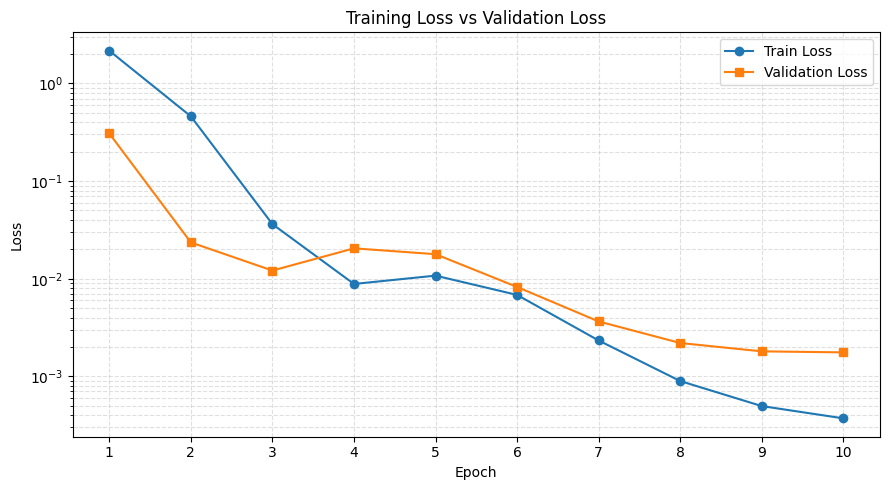

In [51]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.plot(epochs, val_losses, marker="s", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.xticks(epochs)

plt.yscale("log")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 9. 文本生成与推理

训练前向在完整已知对话上计算目标概率；`model.generate()` 则从只有 user 问题的 Prompt 开始，自回归地产生新 Token：根据已有上下文预测、选取新 ID、拼接到上下文，再继续预测。推理不需要传入训练 labels。

| 参数 | 本 Cell 的值 / 含义 |
|---|---|
| `add_generation_prompt=True` | 将输入结束在等待回答的 assistant 前缀 |
| `input_ids` | 编码后的 Prompt，先移到模型所在设备 |
| `attention_mask` | 显式标记有效 Prompt 位置，尤其有 Padding 或 pad/eos 复用时应避免仅凭 ID 猜测 |
| `max_new_tokens=16` | 最多新增 16 个 Token，不包含已有 Prompt；遇到生效的 EOS 可提前停止 |
| `do_sample=False` | 不做随机采样；当前模型生成配置的常规单束设置下按贪心方式选择 |
| `eos_token_id` | 指定序列结束标记，生成到对应 ID 时可结束 |
| `pad_token_id` | 指定生成流程使用的填充 ID，不是要求模型输出的答案内容 |

Decoder-only 模型返回的 `output_ids` 包含 **Prompt + 新增 Token**。因此用 `output_ids[0, input_ids.shape[1]:]` 去掉第一个样本的输入部分，再由 `tokenizer.decode(..., skip_special_tokens=True)` 将 ID 转为文本并隐藏特殊标记。此处的索引写法针对当前单样本，不是多样本各自截取和停止的完整实现。

`model.eval()` 关闭训练模式行为；`torch.no_grad()` 关闭梯度记录；代码不调用 backward 或 optimizer，因此不更新参数。二者职责不同，eval 本身不禁止自动求导，也不冻结参数。

保存输出中模型回答“5”。这个问题就在训练集中，可作为生成链路工作的例子；它不是独立泛化测试，也不能证明模型刚学会加法。

In [52]:
model.eval()

test_messages = [
    {"role": "user", "content": "2 + 3 等于多少？"}
]

prompt = tokenizer.apply_chat_template(
    test_messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)
input_ids = prompt["input_ids"].to(device)
attention_mask = prompt["attention_mask"].to(device)

with torch.no_grad():
    output_ids = model.generate(
        input_ids=input_ids,
        attention_mask=attention_mask,
        max_new_tokens=16,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

new_tokens = output_ids[0, input_ids.shape[1]:]
answer = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print("模型回答：", answer)

模型回答： 5


## 10. 基础模型与 LoRA 的比较

### 10.1 相同训练 Batch 上的 Loss 对照

`model.disable_adapter()` 是一个上下文管理器：进入作用域时临时绕过 Adapter 分支，使用冻结的基础模型行为；离开后恢复 Adapter。它不删除 Adapter、不把基础模型参数重置，也不会训练出另一份模型。当前代码没有合并 Adapter，因此可以用这一开关进行对照。

本 Cell 从 **train_dataloader** 取同一个 Batch，固定输入、mask 与 labels，在 eval/no_grad 下分别关闭和启用 Adapter。这让主要差异集中在 Adapter，而不是由不同问题、标签或训练模式造成。虽然 DataLoader 开启了 shuffle，本例一批包含全部两条训练样本。

保存输出：

| 同一训练 Batch | Loss |
|---|---:|
| 关闭 Adapter：基础模型 | 2.1618 |
| 启用 Adapter：LoRA 模型 | 0.0003 |
| 基础值减 LoRA 值 | 2.1615 |

这些值来自训练后的评估模式前向；0.0003 与最后一轮训练日志的 0.0004 在计算时点、模式上不同，不能当成矛盾。它说明 LoRA 更贴合这两条训练目标，不是验证集结论。Loss 差值也不是正确率提升的百分点。

In [53]:

eval_batch = next(iter(train_dataloader))
eval_batch = {
    key: value.to(device)
    for key, value in eval_batch.items()
}

model.eval()

with torch.no_grad():
    with model.disable_adapter():
        base_loss = model(**eval_batch).loss.item()

    lora_loss = model(**eval_batch).loss.item()

print(f"基础模型 Loss: {base_loss:.4f}")
print(f"LoRA 模型 Loss: {lora_loss:.4f}")
print(f"Loss 差值: {base_loss - lora_loss:.4f}")

基础模型 Loss: 2.1618
LoRA 模型 Loss: 0.0003
Loss 差值: 2.1615


### 10.2 固定输入与生成设置，观察回答差异

`generate_answer(question, use_lora)` 为同一个问题构造相同聊天模板，在两条分支中使用相同的生成上限 **48 个新 Token**、非采样设置、pad 与 eos ID。`use_lora=False` 时在 `disable_adapter()` 作用域内生成，另一分支启用 Adapter；其余输入处理保持一致。

pad ID 存在时直接使用，否则退回 eos ID。输入仍显式传入 attention_mask；退回 eos 并不意味着模型可以区分所有填充场景而无需 mask。

原输出中的对照包括：

| 问题 | 基础模型输出 | LoRA 输出 |
|---|---|---|
| 7 + 8 等于多少？ | 7 + 8 等于 15。 | 15 |
| 日本的首都是哪里？ | 日本的首都是东京。 | 东京。 |

**观测**：这两个例子中，两者都给出正确答案，LoRA 的回答更简短。**可能解释**：训练中的短答案格式影响了输出风格；但没有足够样本或定量评估来证明这种解释，更不能据此断言数学或地理能力提高。

第三个问题是机器学习的一句话定义，原输出展示了两种表述，没有自动评分或人工评估量表。48 Token 上限也可能截断回答，因此仅凭打印文本不能公平评价完整回答质量。

本函数每次只建立当前问题的 messages，不保留上一轮对话历史。它是单轮生成对照，不是具备多轮记忆的聊天系统。

In [54]:
model.eval()

test_questions = [
    "7 + 8 等于多少？",
    "日本的首都是哪里？",
    "请用一句话解释什么是机器学习。"
]

def generate_answer(question, use_lora):
    messages = [
        {"role": "user", "content": question}
    ]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )
    input_ids = prompt["input_ids"].to(device)
    attention_mask = prompt["attention_mask"].to(device)
    with torch.no_grad():
        if use_lora:
            output_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=48,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
                    if tokenizer.pad_token_id is not None
                    else tokenizer.eos_token_id,
                eos_token_id=tokenizer.eos_token_id
            )
        else:
            with model.disable_adapter():
                output_ids = model.generate(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    max_new_tokens=48,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id
                        if tokenizer.pad_token_id is not None
                        else tokenizer.eos_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )
    new_tokens = output_ids[0, input_ids.shape[1]:]
    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

for question in test_questions:
    print(f"\n问题：{question}")

    base_answer = generate_answer(question, use_lora=False)
    lora_answer = generate_answer(question, use_lora=True)

    print("基础模型：", base_answer)
    print("LoRA 模型：", lora_answer)
    print("-" * 50)


问题：7 + 8 等于多少？
基础模型： 7 + 8 等于 15。
LoRA 模型： 15
--------------------------------------------------

问题：日本的首都是哪里？
基础模型： 日本的首都是东京。
LoRA 模型： 东京。
--------------------------------------------------

问题：请用一句话解释什么是机器学习。
基础模型： 机器学习是一种人工智能的分支，它使计算机系统能够通过数据自动改进和优化其性能，无需明确编程或有预先设定的目标。在机器学习中，算法被设计用来从数据中学习模式、规则和特征
LoRA 模型： 通过教计算机自动从数据中学习，从而使计算机在没有被特别编程的情况下也达到专家水平。
--------------------------------------------------


### 10.3 在相同验证样本上比较：从训练贴合走向有限的外部检查

下面重新列出与前面相同的两条验证对话，而不是新增测试集；继续按模板编码，只监督 assistant 区域，逐条关闭/启用 Adapter，保持输入与目标一致。

| 验证样本 | 基础模型 Loss | LoRA Loss |
|---|---:|---:|
| 9 + 6 → 15 | 1.1142 | 0.0009 |
| 意大利首都 → 罗马。 | 1.6247 | 0.0026 |
| 两条样本的平均值 | 1.3694 | 0.0018 |

上表直接引用保存输出的四位小数。平均值来自原始浮点 Loss 的平均，展示时分别舍入，不应仅用已舍入的行数值追求完全一致的末位。

**可以得出的结论**：在当前两条验证样本、当前模板和标签规则下，启用 Adapter 后的参考答案交叉熵更低；这与第 10 轮验证日志显示的 0.0018 相符。

**不能得出的结论**：模型已学会一般算术、整体知识更准确、通用能力提升或已经排除过拟合。验证只含两个与训练相近的短问答，Loss 还包括结束与换行 Token；没有在广泛分布上统计自由生成的正确率。基础模型在其他生成示例中本来就能回答正确，也说明低参考答案 Loss 与“是否具备某项知识”不是同一问题。

后续若要评估泛化，需要更丰富且与训练隔离的数据、明确的任务指标，以及不同随机运行的稳定性检查；这些是延伸方向，本 Notebook 尚未实现。

In [55]:
validation_examples = [
    [
        {"role": "user", "content": "9 + 6 等于多少？"},
        {"role": "assistant", "content": "15"}
    ],
    [
        {"role": "user", "content": "意大利的首都是哪里？"},
        {"role": "assistant", "content": "罗马。"}
    ]
]

model.eval()

base_losses = []
lora_losses = []

for i, messages in enumerate(validation_examples, start=1):
    full_ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    prompt_ids = tokenizer.apply_chat_template(
        messages[:-1],
        tokenize=True,
        add_generation_prompt=True
    )

    assert full_ids[:len(prompt_ids)] == prompt_ids

    target_ids = full_ids.copy()
    target_ids[:len(prompt_ids)] = [-100] * len(prompt_ids)

    val_input_ids = torch.tensor(
        [full_ids], dtype=torch.long, device=device
    )
    val_labels = torch.tensor(
        [target_ids], dtype=torch.long, device=device
    )
    val_attention_mask = torch.ones_like(val_input_ids)

    with torch.no_grad():
        with model.disable_adapter():
            base_loss = model(
                input_ids=val_input_ids,
                attention_mask=val_attention_mask,
                labels=val_labels
            ).loss.item()

        lora_loss = model(
            input_ids=val_input_ids,
            attention_mask=val_attention_mask,
            labels=val_labels
        ).loss.item()

    base_losses.append(base_loss)
    lora_losses.append(lora_loss)

    print(f"验证样本 {i}")
    print("问题：", messages[0]["content"])
    print(f"基础模型 Loss：{base_loss:.4f}")
    print(f"LoRA 模型 Loss：{lora_loss:.4f}")
    print("-" * 40)

print(
    f"基础模型平均验证 Loss："
    f"{sum(base_losses) / len(base_losses):.4f}"
)
print(
    f"LoRA 模型平均验证 Loss："
    f"{sum(lora_losses) / len(lora_losses):.4f}"
)

验证样本 1
问题： 9 + 6 等于多少？
基础模型 Loss：1.1142
LoRA 模型 Loss：0.0009
----------------------------------------
验证样本 2
问题： 意大利的首都是哪里？
基础模型 Loss：1.6247
LoRA 模型 Loss：0.0026
----------------------------------------
基础模型平均验证 Loss：1.3694
LoRA 模型平均验证 Loss：0.0018


## 11. 保存与重新加载 Adapter

### 11.1 保存了哪些资源

此时 `model` 是 PEFT 包装后的模型，`model.save_pretrained()` 保存 Adapter 权重与配置；`tokenizer.save_pretrained()` 则保存分词器和模板资源。两次调用职责不同：

| 文件 | 作用 |
|---|---|
| `adapter_model.safetensors` | 已训练的 Adapter 参数，本例主要是各目标层的 A、B |
| `adapter_config.json` | 记录基础模型标识、r、alpha、Dropout、target_modules 等接入配置 |
| `tokenizer.json`、`vocab.json`、`merges.txt` 等 | 分词所需的词表与规则资源 |
| `tokenizer_config.json`、`chat_template.jinja` 等 | 分词器设置、特殊 Token 与聊天模板 |

**Adapter 不是完整基础模型**：保存的增量依赖原始权重 $W_0$ 才能计算结果；本代码没有合并权重后导出独立完整模型。即使 Adapter 目录内保存了 Tokenizer，也仍需另外获得对应基础模型。

`Path("./qwen2_5_0_5b_lora_adapter")` 相对于 Notebook 内核的当前工作目录。历史输出路径是 `D:\LLM-learning\llm-finetuning\qwen2_5_0_5b_lora_adapter`；在其他工作目录运行时，相对路径并不自动相对于 Notebook 文件。这与后面脚本按 `__file__` 定位目录的做法不同。

### 11.2 先加载基础模型，再装回 Adapter

代码删除旧模型与优化器后，先从保存目录恢复 Tokenizer，再按 `MODEL_NAME` 加载基础模型，最后调用 `PeftModel.from_pretrained(base_model_for_reload, adapter_dir)` 接入已有 Adapter。它读取配置和权重，不需要重新训练 LoRA。

两个资源加载调用使用 `local_files_only=True`：只读本地文件或已有模型缓存，缺失时会报错，不会自动联网补齐。Adapter 配置记录模型标识不等于已经把基础权重打包进去。重新加载仍须确保基础模型版本、Tokenizer、聊天模板和词表兼容，否则相同文本的 ID 或模块含义可能改变。

此处未显式传入 `is_trainable`，PEFT 的默认值为 False，适合加载后推理；如果未来要继续训练，需要另行设置可训练状态并重建优化器，不能认为一次加载自动恢复完整训练状态。本代码也没有保存优化器、随机状态或训练进度，因此不是完整的断点续训方案。

最后再次调用前面定义的 `generate_answer()`。该函数读取当前全局 model、tokenizer，因此使用的是新加载对象；保存输出回答仍为“5”，支持“保存与重载后的该样例推理可用”，并不等于已做全部参数逐项一致性检查。

In [57]:
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

adapter_dir = Path("./qwen2_5_0_5b_lora_adapter")
model.save_pretrained(str(adapter_dir))
tokenizer.save_pretrained(str(adapter_dir))

print("保存位置：", adapter_dir.resolve())
print("保存的文件：")
for file_path in sorted(adapter_dir.iterdir()):
    print(file_path.name)

del model, optimizer

if torch.cuda.is_available():
    torch.cuda.empty_cache()

tokenizer = AutoTokenizer.from_pretrained(
    str(adapter_dir),
    local_files_only=True
)
base_model_for_reload = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    local_files_only=True
).to(device)
model = PeftModel.from_pretrained(
    base_model_for_reload,
    str(adapter_dir)
).to(device)

model.eval()
del base_model_for_reload

answer = generate_answer("2 + 3 等于多少？", use_lora=True)
print("重新加载后的 LoRA 回答：", answer)

保存位置： D:\LLM-learning\llm-finetuning\qwen2_5_0_5b_lora_adapter
保存的文件：
adapter_config.json
adapter_model.safetensors
added_tokens.json
chat_template.jinja
merges.txt
README.md
special_tokens_map.json
tokenizer.json
tokenizer_config.json
vocab.json
重新加载后的 LoRA 回答： 5


## 12. 独立推理脚本与 Python 环境

本节结合当前同目录的 [inference_lora.py](inference_lora.py) 说明部署到独立进程的最小推理路径，仅作 Markdown 讲解，不执行或改写脚本。

### 12.1 脚本不继承 Notebook 的变量

Notebook 的 Kernel 会保留已执行 Cell 的对象；终端运行脚本会启动新 Python 进程，因此必须自行导入依赖、定位资源、加载 Tokenizer、基础模型与 Adapter。脚本没有训练数据、优化器或训练循环，不会从 Notebook 内存中取得已训练模型。

真实加载顺序是：

1. `Path(__file__).resolve().parent` 定位脚本所在目录，再拼接 `qwen2_5_0_5b_lora_adapter`；因此 Adapter 路径不依赖终端当前目录。
2. 选择可用的 CUDA，否则用 CPU；从 Adapter 目录读取 Tokenizer。
3. 用固定标识 `Qwen/Qwen2.5-0.5B-Instruct` 加载基础模型。
4. 用 `PeftModel.from_pretrained(..., is_trainable=False)` 加载 Adapter，然后将整体模型移到 device 并切到 eval。

Tokenizer 和基础模型加载都设置了 `local_files_only=True`，所以基础权重必须已在本地模型缓存中、Adapter 目录也必须完整。环境变量或账户改变造成缓存位置不同，也可能使原本可运行的模型在另一终端中无法找到；脚本不会为此自动重新下载。

### 12.2 generate_answer() 的完整推理路径

脚本函数接收一个问题字符串，构造单条 user 消息，通过 Chat Template 返回输入张量字典，再把所有字段移动到设备。在 `torch.no_grad()` 下，以 `max_new_tokens=128`、`do_sample=False`、明确的 attention_mask / pad / eos 设置生成；最后裁掉 Prompt ID、解码新增 Token，并 `strip()` 去掉首尾空白。

脚本的 128 与 Notebook 生成对照的 48、训练题演示的 16 是不同上限，不应混为同一次实验配置。脚本顶部的模型加载只进行一次，之后由 `while True` 反复接收问题；输入 q、quit、exit 时退出，空输入被跳过。每次只提交当前问题，没有多轮对话历史。

### 12.3 为什么 Notebook 正常而终端可能导入失败

Notebook 保存的内核名称是 d2l，元数据记录 Python 3.9.25；实际 Kernel 与终端 `python` 可能指向不同解释器。Notebook 中安装过 PEFT，不代表另一个 Python 环境也已安装。脚本直接需要 `torch`、`transformers`、`peft`；Notebook 绘图还使用 `matplotlib`，`pathlib` 则属于标准库。

可在 Notebook 中查看 `sys.executable`，在终端用下面的只读命令查看解释器及安装信息，再选择同一环境执行。以下只是复习命令示例，本次没有运行脚本或安装依赖：

```powershell
python -c "import sys; print(sys.executable)"
python -m pip show torch transformers peft
```

从仓库根目录运行脚本的路径为：

```powershell
python .\llm-finetuning\inference_lora.py
```

运行前应先选择所需环境，或把 python 替换成该环境解释器的完整路径。解释器决定使用哪些包，缓存决定是否能找到本地模型，Adapter 目录保存微调增量：三者职责不同。当前 Notebook 没有保存终端交互记录，因此这里只能确认脚本实现了上述流程，不能声称本次已验证终端运行成功。

## 13. 总结与下一阶段

### 本次实验完成了什么

根据已有代码与保存输出，已串起 Qwen2.5-0.5B-Instruct 的聊天格式化、回答区域标签屏蔽、动态批处理、基础模型 Loss、LoRA 接入、手写训练与验证、Loss 可视化、开关 Adapter 的生成/Loss 对照，以及 Adapter 保存和重载后的样例推理。同目录另有独立交互推理脚本，其实现已在上一节解释。

### 应掌握的核心概念

- **数据与目标**：input_ids 决定模型看见什么，attention_mask 标记有效上下文，labels 与 -100 决定哪些目标产生监督；因果 LM 内部对齐下一 Token。
- **适配与优化**：LoRA 用低秩增量减少可训练参数；冻结权重、train/eval 模式、是否记录梯度、是否执行 optimizer 更新是不同维度。
- **训练与推理**：teacher forcing 的参考答案 Loss 与自由生成的答案质量不同；eval 不等于 no_grad，低 Loss 也不等于高正确率。
- **评估与复现**：相同输入与配置下开关 Adapter 才便于归因；保存 Adapter 不等于保存基础模型，也不等于保存完整续训状态。

### 实验局限

训练和验证各只有两条样本，验证题型接近训练，生成对照也很少；没有足够证据评价泛化、排除过拟合或宣称整体能力提升。实验没有多随机种子统计、自动早停、最佳检查点选择、完整断点续训或标准化生成评测，也没有量化训练。训练与验证的时点、模式和平均口径应在解读曲线时一并考虑。

### 下一阶段：先 Trainer，再 SFTTrainer

先学习 **Hugging Face Trainer**，把当前手写循环中的数据批处理、训练参数、评估、日志与检查点逐一对应起来，理解框架封装了哪些环节。随后学习 **TRL 的 SFTTrainer**，重点比较对话数据组织、数据整理和回答区域 Loss 的处理方式。它们是下一阶段的学习计划，当前 Notebook 尚未实现；本次笔记也没有提前改写训练代码。